# S4b — Segmentation et anomalies avec 5 features (sans redondance)

Projet Math en assurance et finance · 5INFINI · données du 02/01/2023 au 03/11/2026.

**Pourquoi ce notebook.** Dans la matrice de corrélation des 7 features (S3), deux paires sont presque des doublons :
- **skewness et kurtosis** : corrélation de Pearson 0,92 ;
- **VaR 95 % et CVaR 95 %** : corrélation de Pearson 0,89 (0,95 en Spearman).

Garder les deux features d'une paire revient à compter **deux fois la même information** dans les distances de k-means et d'Isolation Forest. On garde donc **une feature par paire**, soit 5 features, et on refait exactement la démarche de la S4 (espace 7F, k = 3).

**Entrées** (lecture seule, rien n'est modifié) :
- `data/s3/features_titres.csv` : 75 titres × 7 features ;
- `data/processed/qualite_par_titre.csv` : nom et liquidité ;
- `data/processed/s4/resultats_par_titre.csv` : résultats de la S4 (7 features), pour la comparaison.

**Sorties** : `data/processed/s4_5f/`.

**Plan.**
0. Chargement
1. Corrélations et choix des 5 features
2. Standardisation
3. k-means : choix de k
4. k-means : modèle retenu et interprétation
5. Isolation Forest
6. Nature des anomalies
7. Comparaison avec la S4 (7 features)
8. Titres liquides seulement
9. Synthèse

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score

GRAINE = 42                       # même graine qu'en S4
K_PLAGE = range(3, 9)             # même plage qu'en S4
TAUX_IF = [0.03, 0.05, 0.08, 0.10]
TAUX_RETENU = 0.05
SEUIL_LIQUIDITE = 0.60

RACINE = Path("..")               # le notebook est dans notebooks/
F_PATH = RACINE / "data" / "s3" / "features_titres.csv"
Q_PATH = RACINE / "data" / "processed" / "qualite_par_titre.csv"
S4_PATH = RACINE / "data" / "processed" / "s4" / "resultats_par_titre.csv"
OUT = RACINE / "data" / "processed" / "s4_5f"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 170, "display.max_columns", 20, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
LIB = {"rendement_annualise": "rendement", "volatilite_annualisee": "volatilité", "skewness": "skewness",
       "kurtosis": "kurtosis", "var_95": "VaR", "cvar_95": "CVaR", "beta": "bêta"}

## 0. Chargement

In [2]:
F_brut = pd.read_csv(F_PATH); Q_brut = pd.read_csv(Q_PATH); S4_brut = pd.read_csv(S4_PATH)
print("features :", F_brut.shape, list(F_brut.columns))
print("résultats S4 : colonnes utilisées présentes :", {"cluster_7F", "signale_if_7F", "nb_signalements_sur_12"} <= set(S4_brut.columns))

F7 = F_brut.set_index("ticker")
Q = Q_brut.dropna(subset=["ticker"]).set_index("ticker").loc[F7.index]
info = Q[["nom", "part_seances_echangees", "part_rendements_nuls", "retenu"]].copy()
info["liquide"] = info["retenu"].astype(bool)
S4 = S4_brut.set_index("ticker").loc[F7.index]
assert F7.shape == (75, 7) and F7.notna().all().all()
print(f"{len(F7)} titres, dont {info.liquide.sum()} liquides")

features : (75, 8) ['ticker', 'rendement_annualise', 'volatilite_annualisee', 'skewness', 'kurtosis', 'var_95', 'cvar_95', 'beta']
résultats S4 : colonnes utilisées présentes : True
75 titres, dont 57 liquides


## 1. Corrélations et choix des 5 features

On calcule les corrélations entre features **sur les 75 titres** (une valeur de feature par titre), en Pearson et en Spearman (rangs, moins sensible aux valeurs extrêmes comme le kurtosis de PLTU).

Paires les plus corrélées (Pearson) :
 feature_1 feature_2  pearson  spearman
  skewness  kurtosis     0.92      0.58
volatilité       VaR    -0.91     -0.93
       VaR      CVaR     0.89      0.95
volatilité      CVaR    -0.85     -0.88
  skewness      CVaR     0.59      0.89
  kurtosis      CVaR     0.56      0.68


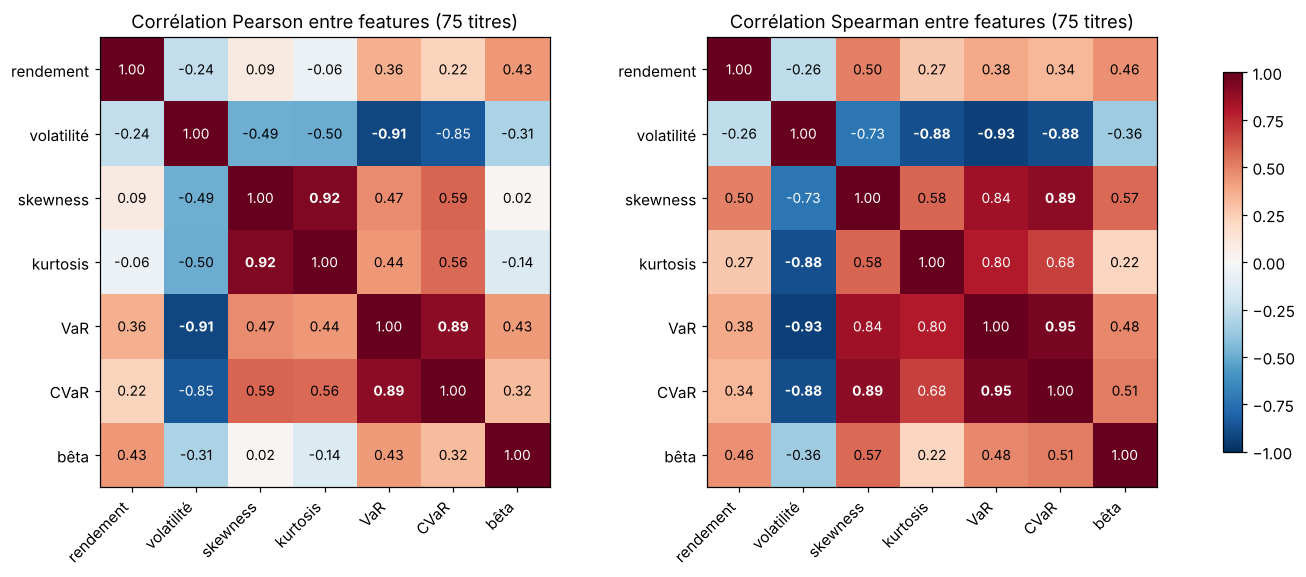

In [3]:
corr_p = F7.corr(method="pearson"); corr_s = F7.corr(method="spearman")
corr_p.to_csv(OUT / "correlations_features_pearson.csv"); corr_s.to_csv(OUT / "correlations_features_spearman.csv")

paires = []
cols = list(F7.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        paires.append({"feature_1": LIB[cols[i]], "feature_2": LIB[cols[j]],
                       "pearson": corr_p.iloc[i, j], "spearman": corr_s.iloc[i, j]})
paires = pd.DataFrame(paires).assign(abs_pearson=lambda d: d.pearson.abs()).sort_values("abs_pearson", ascending=False).drop(columns="abs_pearson")
print("Paires les plus corrélées (Pearson) :")
print(paires.head(6).round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.6)); fig.subplots_adjust(wspace=0.35)
for a, (m, t) in zip(ax, [(corr_p, "Pearson"), (corr_s, "Spearman")]):
    im = a.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    a.set_xticks(range(7)); a.set_yticks(range(7))
    a.set_xticklabels([LIB[c] for c in m.columns], rotation=45, ha="right"); a.set_yticklabels([LIB[c] for c in m.index])
    for i in range(7):
        for j in range(7):
            v = m.values[i, j]
            a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else "black",
                   fontweight="bold" if (abs(v) >= 0.85 and i != j) else "normal")
    a.set_title(f"Corrélation {t} entre features (75 titres)"); a.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(OUT / "s4b_correlations_features.png", dpi=150, bbox_inches="tight"); plt.show()

**Règle pour choisir quelle feature garder dans chaque paire.** Dans une paire redondante, on retire la feature qui est **la plus corrélée, en moyenne, aux cinq autres features**. On garde ainsi celle qui apporte le plus d'information propre.

In [4]:
absc = corr_p.abs()
choix = []
for a, b in [("skewness", "kurtosis"), ("var_95", "cvar_95")]:
    autres = [c for c in F7.columns if c not in (a, b)]
    ma, mb = absc.loc[a, autres].mean(), absc.loc[b, autres].mean()
    retire = a if ma > mb else b
    choix.append({"paire": f"{LIB[a]} / {LIB[b]}", "pearson": corr_p.loc[a, b], "spearman": corr_s.loc[a, b],
                  f"corr_moy_{LIB[a]}": ma, f"corr_moy_{LIB[b]}": mb, "retiree": LIB[retire], "gardee": LIB[b if retire == a else a]})
CHOIX_F = pd.DataFrame(choix); print(CHOIX_F.round(3).to_string(index=False))
RETIREES = [c for c in F7.columns if LIB[c] in CHOIX_F.retiree.values]
FEATURES5 = [c for c in F7.columns if c not in RETIREES]
F = F7[FEATURES5]
print("\n5 features retenues :", [LIB[c] for c in FEATURES5])
print("Plus forte corrélation restante :",
      F.corr().where(~np.eye(5, dtype=bool)).abs().stack().idxmax(), round(F.corr().where(~np.eye(5, dtype=bool)).abs().max().max(), 2))
CHOIX_F.to_csv(OUT / "choix_features.csv", index=False)

              paire  pearson  spearman  corr_moy_skewness  corr_moy_kurtosis  retiree   gardee  corr_moy_VaR  corr_moy_CVaR
skewness / kurtosis    0.924     0.581               0.33              0.339 kurtosis skewness           NaN            NaN
         VaR / CVaR    0.894     0.946                NaN                NaN      VaR     CVaR         0.521          0.508

5 features retenues : ['rendement', 'volatilité', 'skewness', 'CVaR', 'bêta']
Plus forte corrélation restante : ('volatilite_annualisee', 'cvar_95') 0.85


**Lecture.**
- **Kurtosis retiré, skewness gardé.** L'écart de corrélation moyenne est faible (0,339 contre 0,330), mais deux autres raisons vont dans le même sens : le kurtosis est dominé par une seule valeur extrême (164 pour PLTU), et le skewness garde le **sens** de l'asymétrie (gains ou pertes extrêmes), que le kurtosis ne donne pas.
- **VaR retirée, CVaR gardée.** La VaR est un peu plus corrélée au reste (0,521 contre 0,508), surtout à la volatilité (−0,91). La CVaR est aussi la mesure la plus solide en théorie : c'est une mesure de risque *cohérente*, qui regarde toute la queue des pertes et pas un seul quantile.
- **Il reste une corrélation forte : volatilité / CVaR (−0,85).** On la garde volontairement : la volatilité mesure la dispersion « normale », la CVaR les pertes extrêmes, et ce sont deux notions de risque différentes. Si on les fusionnait, on reviendrait à 4 features ; c'est une variante possible à discuter.

## 2. Standardisation

Chaque feature est centrée et réduite sur les 75 titres, comme en S4.

In [5]:
def standardiser(F):
    return pd.DataFrame(StandardScaler().fit_transform(F), index=F.index, columns=F.columns)
Z = standardiser(F)
print("moyennes ≈ 0 :", np.allclose(Z.mean(), 0), "| écarts-types = 1 :", np.allclose(Z.std(ddof=0), 1))

moyennes ≈ 0 : True | écarts-types = 1 : True


## 3. k-means : choix de k

Même règle qu'en S4 : k de 3 à 8, k-means++ avec 50 initialisations et la graine 42. Quatre critères votent (coude, silhouette, Calinski-Harabasz, Davies-Bouldin) ; on retient le k qui a le plus de votes, la silhouette départage les égalités.

On calcule aussi, **à titre de contrôle**, k = 2, 9 et 10 : ils ne participent pas au vote, mais ils disent si le k retenu au bord de la plage est un vrai optimum.

In [6]:
def coude(ks, inerties):
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.array(inerties) - min(inerties)) / (max(inerties) - min(inerties))
    return ks[int(np.argmax((1 - x) - y))]

def kmeans(X, k):
    return KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=GRAINE).fit(X)

def criteres(X, ks):
    lignes = []
    for k in ks:
        km = kmeans(X, k); tailles = np.bincount(km.labels_)
        lignes.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                       "calinski_harabasz": calinski_harabasz_score(X, km.labels_), "davies_bouldin": davies_bouldin_score(X, km.labels_),
                       "tailles": " / ".join(map(str, sorted(tailles, reverse=True))), "nb_singletons": int((tailles == 1).sum())})
    return pd.DataFrame(lignes).set_index("k")

def choix_k(X, nom):
    t = criteres(X, K_PLAGE); ks = list(t.index)
    votes = {"coude": coude(ks, t.inertie.tolist()), "silhouette": int(t.silhouette.idxmax()),
             "calinski_harabasz": int(t.calinski_harabasz.idxmax()), "davies_bouldin": int(t.davies_bouldin.idxmin())}
    compte = pd.Series(list(votes.values())).value_counts()
    meilleurs = compte[compte == compte.max()].index.tolist()
    k = int(max(meilleurs, key=lambda kk: t.silhouette[kk]))
    hors = criteres(X, [2, 9, 10])[["silhouette", "tailles"]]
    print(f"{nom} : votes {votes} → k retenu = {k} (silhouette {t.silhouette[k]:.3f}, tailles {t.tailles[k]})")
    print("   contrôle hors plage :", ", ".join(f"k={kk} silhouette {r.silhouette:.3f}" for kk, r in hors.iterrows()))
    return t, votes, k, hors

TABK, VOTES, K, HORS = choix_k(Z, "5F, 75 titres")
TABK.to_csv(OUT / "choix_k_criteres.csv"); HORS.to_csv(OUT / "choix_k_controle_hors_plage.csv")
TABK[["inertie", "silhouette", "calinski_harabasz", "davies_bouldin", "tailles"]].round(3)

5F, 75 titres : votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 3} → k retenu = 3 (silhouette 0.365, tailles 46 / 28 / 1)
   contrôle hors plage : k=2 silhouette 0.343, k=9 silhouette 0.255, k=10 silhouette 0.299


,inertie,silhouette,calinski_harabasz,davies_bouldin,tailles
k,,,,,
3,167.616,0.365,44.541,0.735,46 / 28 / 1
4,130.486,0.293,44.348,0.935,31 / 27 / 16 / 1
5,109.787,0.296,42.275,0.835,28 / 24 / 20 / 2 / 1
6,91.057,0.293,43.033,0.882,27 / 19 / 16 / 10 / 2 / 1
7,80.240,0.278,41.633,0.928,26 / 14 / 13 / 11 / 8 / 2 / 1
8,70.507,0.273,41.336,0.932,22 / 12 / 10 / 10 / 10 / 8 / 2 / 1


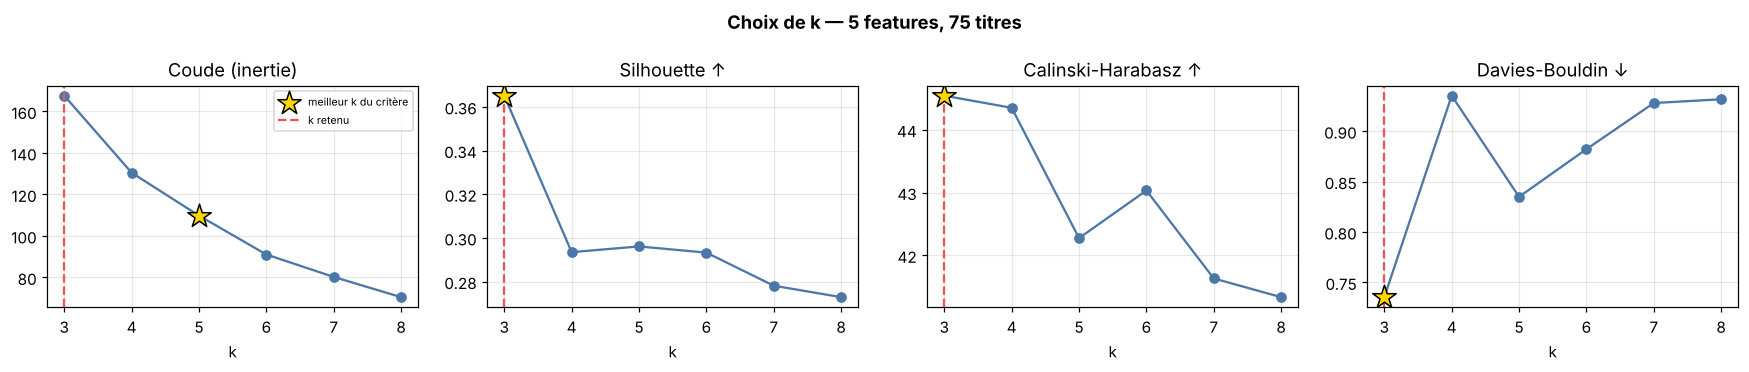

In [7]:
def graph_k(t, k_ret, titre, fichier):
    crit = [("inertie", "Coude (inertie)", None), ("silhouette", "Silhouette ↑", "max"),
            ("calinski_harabasz", "Calinski-Harabasz ↑", "max"), ("davies_bouldin", "Davies-Bouldin ↓", "min")]
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
    for a, (c, lab, sens) in zip(ax, crit):
        a.plot(t.index, t[c], "o-", c="#4C78A8")
        vote = coude(list(t.index), t.inertie.tolist()) if sens is None else (t[c].idxmax() if sens == "max" else t[c].idxmin())
        a.scatter([vote], [t.loc[vote, c]], marker="*", s=260, c="gold", ec="k", zorder=6, label="meilleur k du critère")
        a.axvline(k_ret, c="#E45756", ls="--", lw=1.5, label="k retenu"); a.set_title(lab); a.set_xlabel("k")
    ax[0].legend(fontsize=7)
    fig.suptitle(titre, fontweight="bold"); fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_k(TABK, K, "Choix de k — 5 features, 75 titres", "s4b_choix_k.png")

**Lecture du choix de k.** Trois critères sur quatre (silhouette, Calinski-Harabasz, Davies-Bouldin) votent pour **k = 3**, comme en S4 avec 7 features ; le coude seul propose 5. Le contrôle hors plage confirme que k = 3 est un vrai optimum : k = 2 (0,343) et k = 9-10 (0,26-0,30) ont une silhouette plus basse. La silhouette au k retenu, **0,365**, est un peu plus faible qu'avec 7 features (0,406) : retirer les doublons enlève une partie de la séparation « artificielle » que la redondance créait. La structure de groupes reste **faible** (< 0,5).

## 4. k-means : modèle retenu et interprétation

In [8]:
def ajuster(X, k):
    km = kmeans(X, k); ordre = pd.Series(km.labels_).value_counts().index
    return pd.Series(pd.Series(km.labels_).map({c: i + 1 for i, c in enumerate(ordre)}).values, index=X.index, name="cluster_5F")

def interpreter(cl, F7, info):
    lignes = []
    for c in sorted(cl.unique()):
        t = cl.index[cl == c]
        lignes.append({"cluster": c, "taille": len(t), "titres": ", ".join(sorted(t)),
                       "rendement_median": F7.loc[t, "rendement_annualise"].median(), "volatilite_mediane": F7.loc[t, "volatilite_annualisee"].median(),
                       "skewness_mediane": F7.loc[t, "skewness"].median(), "cvar_mediane": F7.loc[t, "cvar_95"].median(),
                       "beta_median": F7.loc[t, "beta"].median(), "liquidite_mediane": info.loc[t, "part_seances_echangees"].median(),
                       "nb_peu_liquides": int((~info.loc[t, "liquide"]).sum())})
    return pd.DataFrame(lignes)

CL = ajuster(Z, K)
INT = interpreter(CL, F7, info); INT.to_csv(OUT / "interpretation_clusters.csv", index=False)
print(INT.drop(columns="titres").round(3).to_string(index=False))
for _, r in INT.iterrows(): print(f"\ncluster {r.cluster} ({r.taille}) : {r.titres}")

 cluster  taille  rendement_median  volatilite_mediane  skewness_mediane  cvar_mediane  beta_median  liquidite_mediane  nb_peu_liquides
       1      46             0.260               0.226             0.532        -0.031        0.588              0.948                6
       2      28            -0.007               0.327            -0.044        -0.044        0.126              0.692               11
       3       1             0.048               0.048            11.728        -0.000       -0.005              0.040                1

cluster 1 (46) : AB, AL, AMV, ARTES, ASSMA, ATB, ATL, BH, BHASS, BIAT, BNA, BNASS, BT, CC, CIL, CITY, DH, HL, LNDOR, MGR, MPBS, NAKL, OTH, PGH, SAH, SAM, SFBT, SIMPA, SMART, SOTET, SOTUV, SPDIT, STA, STAR, STB, STPIL, TINV, TJARI, TJL, TLNET, TLS, TPR, TRE, UBCI, UIB, UMED

cluster 2 (28) : AETEC, ALKIM, ASSAD, AST, BHL, BL, BTE, CELL, ECYCL, ICF, MAG, MNP, NBL, PLAST, SCB, SIAME, SIPHA, SITS, SMD, SOKNA, SOMOC, SOTEM, STIP, STPAP, TAIR, TGH, UADH, WI

**Lecture des clusters.** On retrouve les trois groupes de la S4 :
- **Cluster 1 (46 titres)** : titres liquides (94,8 % de séances échangées en médiane), rendement médian 26 %, volatilité 23 %, bêta 0,59. Il contient les grandes banques et les titres les plus suivis.
- **Cluster 2 (28 titres)** : rendement médian proche de zéro (−0,7 %), volatilité plus forte (33 %), bêta faible (0,13), et 11 des 18 titres peu liquides.
- **Cluster 3 : PLTU seul**, toujours isolé par son skewness extrême (+8,2σ) et ses prix figés.

Le partage reste donc **liquide et lié au marché / volatil, peu liquide et peu lié au marché**. Les 5 features donnent la même lecture que les 7.

## 5. Isolation Forest

Même réglage qu'en S4 : 500 arbres, graine 42, score = −`score_samples` (plus haut = plus anormal). Le taux de contamination fixe seulement le seuil : on teste 3, 5, 8 et 10 %.

Comme il n'y a ici qu'**un seul espace** (5F), on a 4 tests au lieu de 12. On appelle **anomalie stable** un titre signalé à au moins 3 taux sur 4 (même exigence qu'en S4 : environ deux tiers des tests).

Contrôle OK (seuil par rang = IsolationForest(contamination=taux))

taux  nb_signales                                  titres_signales
  3%            3                                  AB, SIMPA, PLTU
  5%            4                           AB, SIMPA, BHASS, PLTU
  8%            6             AB, SOTET, ALKIM, SIMPA, BHASS, PLTU
 10%            8 BIAT, AB, SOTET, CELL, ALKIM, SIMPA, BHASS, PLTU


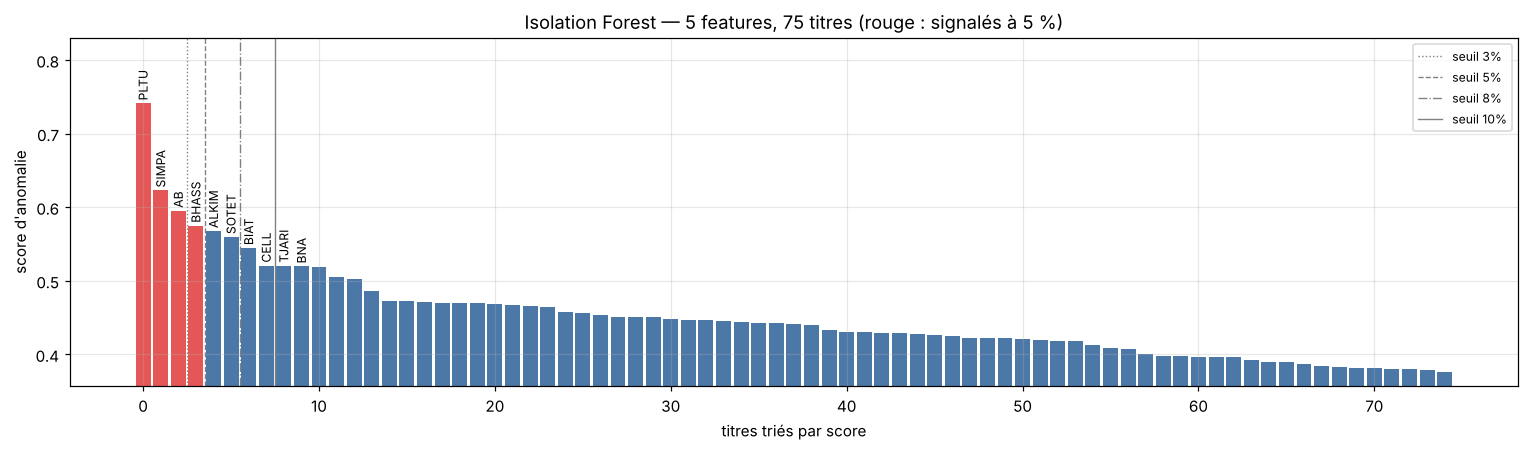

In [9]:
def isolation(X):
    f = IsolationForest(n_estimators=500, contamination="auto", random_state=GRAINE).fit(X)
    s = pd.Series(-f.score_samples(X), index=X.index, name="score_if_5F")
    sig = pd.DataFrame({taux: s.index.isin(s.nlargest(int(np.ceil(taux * len(s)))).index) for taux in TAUX_IF}, index=s.index)
    for taux in TAUX_IF:   # contrôle : identique à IsolationForest(contamination=taux)
        g = IsolationForest(n_estimators=500, contamination=taux, random_state=GRAINE).fit(X)
        assert set(X.index[g.predict(X) == -1]) == set(sig.index[sig[taux]])
    return s, sig

SC, SIG = isolation(Z)
NB = SIG.sum(axis=1).rename("nb_signalements_sur_4")
STAB = pd.DataFrame([{"taux": f"{t:.0%}", "nb_signales": int(SIG[t].sum()), "titres_signales": ", ".join(SIG.index[SIG[t]])} for t in TAUX_IF])
STAB.to_csv(OUT / "stabilite_isolation_forest.csv", index=False)
print("Contrôle OK (seuil par rang = IsolationForest(contamination=taux))\n"); print(STAB.to_string(index=False))

fig, a = plt.subplots(figsize=(14, 4.2))
s = SC.sort_values(ascending=False); n5 = int(np.ceil(TAUX_RETENU * len(s)))
a.bar(range(len(s)), s.values, color=["#E45756" if i < n5 else "#4C78A8" for i in range(len(s))], width=0.85)
for taux, ls in zip(TAUX_IF, [":", "--", "-.", "-"]):
    a.axvline(int(np.ceil(taux * len(s))) - 0.5, ls=ls, c="gray", lw=0.9, label=f"seuil {taux:.0%}")
for i, t in enumerate(s.index[:10]): a.text(i, s.iloc[i] + 0.004, t, rotation=90, ha="center", va="bottom", fontsize=8)
a.set_ylim(s.min() * 0.95, s.max() * 1.12); a.set_xlabel("titres triés par score"); a.set_ylabel("score d'anomalie")
a.set_title("Isolation Forest — 5 features, 75 titres (rouge : signalés à 5 %)"); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "s4b_scores_isolation_forest.png", dpi=150); plt.show()

**Lecture.** À 5 %, les 4 titres signalés sont **AB, SIMPA, BHASS et PLTU**, exactement les mêmes qu'avec 7 features dans l'espace 7F. Quatre titres sont stables (au moins 3 taux sur 4) : AB, SIMPA, PLTU et BHASS. SOTET n'apparaît qu'à partir de 8 %.

## 6. Nature des anomalies

Même règle qu'en S4, appliquée sans jugement sur la santé des sociétés :
- **artefact d'illiquidité** si le titre est échangé moins de 60 % des séances ou a plus de 50 % de rendements nuls ;
- sinon **performance extrême** si au moins une des 5 features est à |z| > 2 ;
- sinon **atypique modéré** (isolé par une combinaison de features).

Aucune anomalie n'est présentée comme une société en difficulté : il faudrait une preuve externe.

In [10]:
def nature(t, Z, info):
    i = info.loc[t]; z = Z.loc[t]
    ext = [f"{LIB[f]} {'+' if z[f] > 0 else '−'}{abs(z[f]):.1f}σ" for f in Z.columns if abs(z[f]) > 2]
    if i.part_seances_echangees < SEUIL_LIQUIDITE or i.part_rendements_nuls > 0.5:
        return "artefact d'illiquidité", f"échangé {i.part_seances_echangees:.0%} des séances, {i.part_rendements_nuls:.0%} de rendements nuls" + (f" ; extrêmes : {', '.join(ext)}" if ext else "")
    if ext:
        sens = (" (hausse)" if z.rendement_annualise > 0 else " (baisse)") if abs(z.rendement_annualise) > 2 else ""
        return "performance extrême" + sens, f"liquide ({i.part_seances_echangees:.0%}) ; extrêmes : {', '.join(ext)}"
    return "atypique modéré", f"liquide ({i.part_seances_echangees:.0%}) ; aucune feature à |z| > 2, isolé par une combinaison de features"

def table_anomalies(NB, Z, F7, info, n_tests):
    lignes = []
    for t in NB[NB > 0].sort_values(ascending=False).index:
        n, d = nature(t, Z, info)
        lignes.append({"ticker": t, "nom": info.loc[t, "nom"], f"nb_signalements_sur_{n_tests}": int(NB[t]), "stable": NB[t] >= 3,
                       "rendement": F7.loc[t, "rendement_annualise"], "volatilite": F7.loc[t, "volatilite_annualisee"],
                       "part_seances_echangees": info.loc[t, "part_seances_echangees"], "nature": n, "justification": d})
    return pd.DataFrame(lignes)

ANO = table_anomalies(NB, Z, F7, info, 4); ANO.to_csv(OUT / "nature_anomalies.csv", index=False)
print(ANO.drop(columns=["rendement", "volatilite"]).to_string(index=False))

ticker              nom  nb_signalements_sur_4  stable  part_seances_echangees                       nature                                                                                            justification
    AB        AMEN BANK                      4    True                   0.993              atypique modéré                          liquide (99%) ; aucune feature à |z| > 2, isolé par une combinaison de features
 SIMPA           SIMPAR                      4    True                   0.118       artefact d'illiquidité                échangé 12% des séances, 97% de rendements nuls ; extrêmes : volatilité −2.4σ, CVaR +3.2σ
  PLTU PLAC. TSIE-SICAF                      4    True                   0.040       artefact d'illiquidité échangé 4% des séances, 98% de rendements nuls ; extrêmes : volatilité −2.8σ, skewness +8.2σ, CVaR +3.2σ
 BHASS     BH ASSURANCE                      3    True                   0.096       artefact d'illiquidité                                  échangé

**Lecture.**
- **SIMPA, PLTU et BHASS sont des artefacts d'illiquidité** (4 à 12 % de séances échangées, plus de 90 % de rendements nuls). Leur CVaR est anormalement « bonne » (+3,2σ) : un prix qui ne bouge pas ne perd jamais, ce qui fait croire à un risque nul.
- **AB (Amen Bank) est liquide** et n'a aucune feature extrême à elle seule : c'est la combinaison rendement élevé (47,5 %), volatilité modérée et skewness positif qui l'isole.
- Retirer le kurtosis et la VaR **ne change pas la conclusion** : la plupart des anomalies restent des effets d'illiquidité.

## 7. Comparaison avec la S4 (7 features)

- **Clusters** : tableau croisé des clusters 7F (S4) et 5F, et indice de Rand ajusté (ARI : 1 = partitions identiques, 0 = pas mieux que le hasard).
- **Anomalies** : titres signalés à 5 % avec 7 features et avec 5 features.

In [11]:
ARI = adjusted_rand_score(S4["cluster_7F"], CL)
croise = pd.crosstab(S4["cluster_7F"].rename("cluster 7F (S4)"), CL.rename("cluster 5F"))
print(f"ARI 7F / 5F = {ARI:.3f}\n"); print(croise)
change = CL.index[(croise.idxmax(axis=1).reindex(S4["cluster_7F"]).values != CL.values)]
print("\nTitres qui changent de groupe :", ", ".join(change) if len(change) else "aucun")

a7 = set(S4.index[S4["signale_if_7F"].astype(bool)]); a5 = set(SIG.index[SIG[TAUX_RETENU]])
COMP = pd.DataFrame([{"comparaison": "clusters 7F vs 5F", "valeur": f"ARI = {ARI:.3f}"},
                     {"comparaison": "anomalies 5 % communes", "valeur": ", ".join(sorted(a7 & a5))},
                     {"comparaison": "seulement 7F", "valeur": ", ".join(sorted(a7 - a5)) or "—"},
                     {"comparaison": "seulement 5F", "valeur": ", ".join(sorted(a5 - a7)) or "—"},
                     {"comparaison": "titres qui changent de groupe", "valeur": ", ".join(change) or "—"}])
COMP.to_csv(OUT / "comparaison_7F_vs_5F.csv", index=False); print(); print(COMP.to_string(index=False))

ARI 7F / 5F = 0.798

cluster 5F        1   2  3
cluster 7F (S4)           
1                45   3  0
2                 1  25  0
3                 0   0  1

Titres qui changent de groupe : ICF, WIFAK, TINV, AST

                  comparaison                 valeur
            clusters 7F vs 5F            ARI = 0.798
       anomalies 5 % communes AB, BHASS, PLTU, SIMPA
                 seulement 7F                      —
                 seulement 5F                      —
titres qui changent de groupe  ICF, WIFAK, TINV, AST


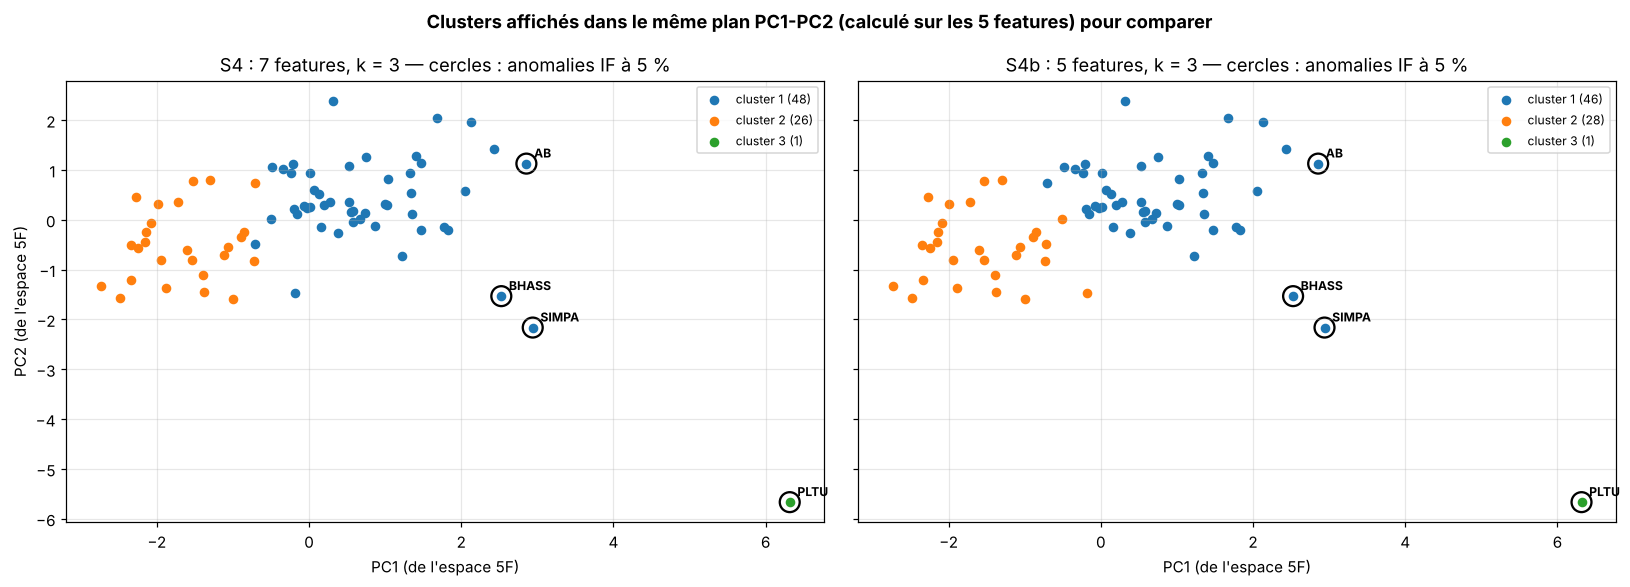

Le plan PC1-PC2 explique 76% de la variance des 5 features (affichage seulement).


In [12]:
pcs = PCA(n_components=2, random_state=GRAINE).fit(Z); P = pd.DataFrame(pcs.transform(Z), index=Z.index, columns=["PC1", "PC2"])
fig, ax = plt.subplots(1, 2, figsize=(15, 5.4), sharex=True, sharey=True)
for a, (lab, titre) in zip(ax, [(S4["cluster_7F"], "S4 : 7 features, k = 3"), (CL, f"S4b : 5 features, k = {K}")]):
    for c in sorted(lab.unique()):
        m = lab == c; a.scatter(P.PC1[m], P.PC2[m], s=28, label=f"cluster {c} ({m.sum()})")
    an = a7 if "7 features" in titre else a5
    for t in an:
        a.scatter(P.PC1[t], P.PC2[t], s=170, facecolors="none", edgecolors="k", lw=1.5)
        a.annotate(t, (P.PC1[t], P.PC2[t]), xytext=(5, 4), textcoords="offset points", fontsize=8, fontweight="bold")
    a.set_title(titre + " — cercles : anomalies IF à 5 %"); a.set_xlabel("PC1 (de l'espace 5F)"); a.legend(fontsize=8)
ax[0].set_ylabel("PC2 (de l'espace 5F)")
fig.suptitle("Clusters affichés dans le même plan PC1-PC2 (calculé sur les 5 features) pour comparer", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "s4b_clusters_7F_vs_5F.png", dpi=150); plt.show()
print(f"Le plan PC1-PC2 explique {pcs.explained_variance_ratio_.sum():.0%} de la variance des 5 features (affichage seulement).")

**Lecture de la comparaison.**
- **ARI = 0,80** : les deux partitions sont très proches. Seuls **4 titres sur 75** changent de groupe : AST, ICF et WIFAK passent du grand cluster au cluster « volatil, peu lié au marché », TINV fait le chemin inverse. Ce sont des titres proches de la frontière entre les deux groupes.
- **Anomalies à 5 % : identiques** (AB, BHASS, PLTU, SIMPA).
- **Conclusion** : les résultats de la S4 n'étaient pas un effet de la redondance des features. Avec 5 features, le modèle est plus simple, sans doublon, et donne les mêmes groupes et les mêmes anomalies.

## 8. Titres liquides seulement

Mêmes étapes sur les 57 titres échangés au moins 60 % des séances, avec une standardisation recalculée sur ces 57 titres.

5F, 57 liquides : votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 8} → k retenu = 3 (silhouette 0.286, tailles 24 / 18 / 15)
   contrôle hors plage : k=2 silhouette 0.361, k=9 silhouette 0.280, k=10 silhouette 0.284


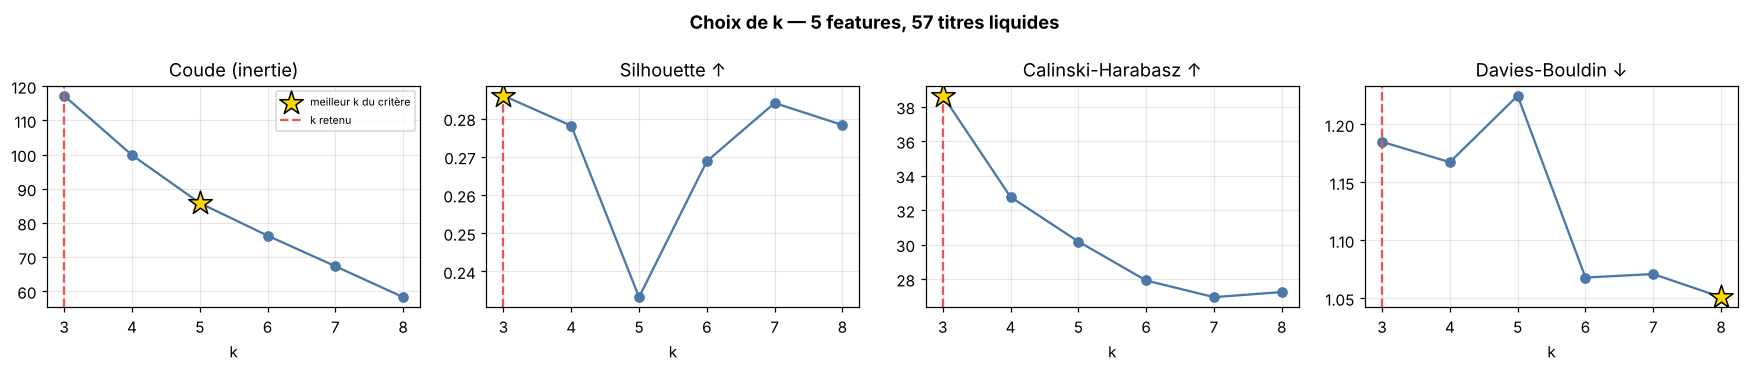

 cluster  taille  rendement_median  volatilite_mediane  skewness_mediane  cvar_mediane  beta_median  liquidite_mediane  nb_peu_liquides
       1      24             0.231               0.249             0.352        -0.035        0.541              0.930                0
       2      18             0.295               0.208             0.784        -0.026        0.774              0.993                0
       3      15            -0.033               0.382            -0.041        -0.045        0.144              0.838                0
cluster 1 (24) : AL, ARTES, ATB, BH, BNASS, CIL, CITY, ICF, LNDOR, MPBS, NAKL, SAM, SOTET, SPDIT, STA, STAR, STB, STPIL, TLNET, TLS, TRE, UIB, UMED, WIFAK
cluster 2 (18) : AB, AMV, ATL, BIAT, BNA, BT, CC, DH, MGR, OTH, PGH, SAH, SFBT, SMART, SOTUV, TJARI, TJL, TPR
cluster 3 (15) : ASSAD, BHL, BTE, CELL, ECYCL, MNP, NBL, PLAST, SCB, SIAME, SOKNA, SOMOC, STPAP, TAIR, TGH



taux  nb_signales                 titres_signales
  3%            2                        AB, CELL
  5%            3                 AB, SOTET, CELL
  8%            5       AB, SOTET, NBL, BHL, CELL
 10%            6 AB, SOTET, TAIR, NBL, BHL, CELL

ticker           nom  nb_signalements_sur_4  stable  part_seances_echangees                       nature                                                                   justification
    AB     AMEN BANK                      4    True                   0.993          performance extrême                           liquide (99%) ; extrêmes : skewness +3.0σ, CVaR +2.0σ
  CELL       CELLCOM                      4    True                   0.694 performance extrême (baisse)                                      liquide (69%) ; extrêmes : rendement −2.2σ
 SOTET       SOTETEL                      3    True                   0.988 performance extrême (hausse)                                      liquide (99%) ; extrêmes : rendement +2.2σ
   NBL N

In [13]:
F57 = F[info.liquide]; info57 = info[info.liquide]; Z57 = standardiser(F57)
TABK57, VOTES57, K57, HORS57 = choix_k(Z57, "5F, 57 liquides")
TABK57.to_csv(OUT / "choix_k_criteres_liquides.csv")
graph_k(TABK57, K57, "Choix de k — 5 features, 57 titres liquides", "s4b_choix_k_liquides.png")
CL57 = ajuster(Z57, K57).rename("cluster_5F_liquides")
INT57 = interpreter(CL57, F7, info); INT57.to_csv(OUT / "interpretation_clusters_liquides.csv", index=False)
print(INT57.drop(columns="titres").round(3).to_string(index=False))
for _, r in INT57.iterrows(): print(f"cluster {r.cluster} ({r.taille}) : {r.titres}")

SC57, SIG57 = isolation(Z57); NB57 = SIG57.sum(axis=1).rename("nb_signalements_sur_4")
STAB57 = pd.DataFrame([{"taux": f"{t:.0%}", "nb_signales": int(SIG57[t].sum()), "titres_signales": ", ".join(SIG57.index[SIG57[t]])} for t in TAUX_IF])
STAB57.to_csv(OUT / "stabilite_isolation_forest_liquides.csv", index=False); print(); print(STAB57.to_string(index=False))
ANO57 = table_anomalies(NB57, Z57, F7, info57, 4); ANO57.to_csv(OUT / "nature_anomalies_liquides.csv", index=False)
print(); print(ANO57.drop(columns=["rendement", "volatilite"]).to_string(index=False))
print("\nARI avec les clusters 7F liquides de la S4 :", round(adjusted_rand_score(S4.loc[CL57.index, "cluster_7F_liquides"], CL57), 3))

**Lecture (57 titres liquides).**
- Le vote retient encore **k = 3** (silhouette, CH), avec des groupes plus équilibrés (24 / 18 / 15) puisque PLTU et les titres figés sont retirés. Mais la silhouette est basse (**0,286**) et **k = 2 ferait mieux (0,361)** dans le contrôle hors plage : chez les titres liquides, k = 3 n'est pas un vrai optimum, la structure de groupes est très faible.
- Les trois groupes se lisent ainsi : un groupe « grandes capitalisations liées au marché » (cluster 2 : BIAT, SFBT, TJARI, AB… ; bêta 0,77), un groupe intermédiaire (cluster 1 ; bêta 0,54) et un groupe volatil, en baisse et peu lié au marché (cluster 3 ; rendement −3 %, volatilité 38 %).
- **Anomalies stables : AB, CELL et SOTET**, toutes liquides et expliquées par des features mesurables (AB : skewness +3,0σ ; CELL : rendement −2,2σ ; SOTET : rendement +2,2σ). Avec 7 features, la S4 trouvait AB, SOTET et WIFAK : AB et SOTET sont confirmés, WIFAK est remplacée par CELL.
- ARI avec les clusters 7F liquides de la S4 : 0,58, donc un accord moyen. Sans les titres illiquides, la partition est plus sensible au choix des features, ce qui confirme que les groupes y sont peu marqués.

## 9. Synthèse

In [14]:
res = info[["nom", "liquide", "part_seances_echangees"]].join(S4[["cluster_7F"]]).join(CL).join(SC).join(NB)
res["signale_if_5F_5pct"] = SIG[TAUX_RETENU].astype(int)
res = res.join(CL57).join(SC57.rename("score_if_5F_liquides")).join(NB57.rename("nb_signalements_sur_4_liquides"))
res.to_csv(OUT / "resultats_par_titre.csv")

ctrl = {"5 features, aucune valeur manquante": F.shape == (75, 5) and F.notna().all().all(),
        "kurtosis et une mesure VaR/CVaR retirés": "kurtosis" in RETIREES and len(RETIREES) == 2,
        "k retenu dans la plage 3-8": K in K_PLAGE and K57 in K_PLAGE,
        "chaque titre a un cluster": CL.notna().all() and CL57.notna().all(),
        "taux 5 % = 4 titres signalés": int(SIG[TAUX_RETENU].sum()) == 4}
for c, ok in ctrl.items(): print(("OK   " if ok else "ÉCHEC"), c)
assert all(ctrl.values())
print("\nFichiers produits :")
for p in sorted(OUT.iterdir()): print("  ", p.name)

OK    5 features, aucune valeur manquante
OK    kurtosis et une mesure VaR/CVaR retirés
OK    k retenu dans la plage 3-8
OK    chaque titre a un cluster
OK    taux 5 % = 4 titres signalés

Fichiers produits :
   choix_features.csv
   choix_k_controle_hors_plage.csv
   choix_k_criteres.csv
   choix_k_criteres_liquides.csv
   comparaison_7F_vs_5F.csv
   correlations_features_pearson.csv
   correlations_features_spearman.csv
   interpretation_clusters.csv
   interpretation_clusters_liquides.csv
   nature_anomalies.csv
   nature_anomalies_liquides.csv
   resultats_par_titre.csv
   s4b_choix_k.png
   s4b_choix_k_liquides.png
   s4b_clusters_7F_vs_5F.png
   s4b_correlations_features.png
   s4b_scores_isolation_forest.png
   stabilite_isolation_forest.csv
   stabilite_isolation_forest_liquides.csv


### Ce qu'il faut retenir

1. **Pourquoi 5 features** : skewness/kurtosis (0,92) et VaR/CVaR (0,89) comptaient deux fois la même information. On garde **rendement, volatilité, skewness, CVaR et bêta**.
2. **k = 3 est confirmé** sur les 75 titres (3 critères sur 4, et vrai optimum hors plage), avec les mêmes trois groupes qu'en S4 : liquide et lié au marché (46), volatil et peu lié au marché (28), PLTU seul.
3. **Les partitions 7F et 5F sont très proches** (ARI 0,80, 4 titres changent de groupe) et les **anomalies à 5 % sont identiques** : AB, BHASS, PLTU, SIMPA.
4. **La conclusion de la S4 tient** : la plupart des anomalies sont des artefacts d'illiquidité ; la redondance des features n'en était pas la cause.
5. **Limite** : la structure de groupes reste faible (silhouette 0,37 ; 0,29 sur les liquides, où k = 2 ferait mieux). Il reste aussi une corrélation forte volatilité/CVaR (−0,85), gardée volontairement car elles mesurent deux risques différents.

Aucune anomalie n'est présentée comme une société en difficulté : il faudrait une preuve externe (états financiers, communiqués du CMF ou de la BVMT).